# <center>**Chapter 14 - Using Activation Functions in Deep Learning Models**<center>

Chương dùng dữ liệu gồm hai vòng tròn không thể tách tuyến tính để so sánh các hàm activation. Notebook vẽ đồ thị các activation, đồng thời theo dõi loss, accuracy và gradient qua từng lớp của MLP.

In [ ]:
import torch
from torch import nn
from torch.optim import Adam
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt

torch.set_num_threads(1)  # Dùng một luồng CPU để các batch nhỏ được xử lý nhanh hơn.
torch.manual_seed(42)

features, targets = make_circles(n_samples=1000, factor=0.5, noise=0.1, random_state=42)
X = torch.tensor(features, dtype=torch.float32)
y = torch.tensor(targets.reshape(-1, 1), dtype=torch.float32)

In [2]:
class CircleMLP(nn.Module):
    def __init__(self, activation):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.Linear(2, 5), nn.Linear(5, 5), nn.Linear(5, 5),
            nn.Linear(5, 5), nn.Linear(5, 1),
        ])
        self.activations = nn.ModuleList([activation() for _ in range(4)])
        self.output_activation = nn.Sigmoid()

    def forward(self, features):
        values = features
        for layer, activation in zip(self.layers[:-1], self.activations):
            values = activation(layer(values))
        return self.output_activation(self.layers[-1](values))

In [3]:
def train_activation(activation, epochs=300, batch_size=32):
    torch.manual_seed(7)
    model = CircleMLP(activation)
    loss_fn = nn.BCELoss()
    optimizer = Adam(model.parameters(), lr=1e-4)
    batch_starts = range(0, len(X), batch_size)
    losses, accuracies, gradient_history = [], [], []
    for epoch in range(epochs):
        model.train()
        epoch_gradients = [[] for _ in model.layers]
        for start in batch_starts:
            X_batch = X[start:start + batch_size]
            y_batch = y[start:start + batch_size]
            loss = loss_fn(model(X_batch), y_batch)
            optimizer.zero_grad()
            loss.backward()
            for index, layer in enumerate(model.layers):
                epoch_gradients[index].append(layer.weight.grad.abs().mean().item())
            optimizer.step()
        model.eval()
        with torch.no_grad():
            probabilities = model(X)
            losses.append(loss_fn(probabilities, y).item())
            accuracies.append(((probabilities >= 0.5) == y).float().mean().item())
        gradient_history.append([sum(values) / len(values) for values in epoch_gradients])
        if (epoch + 1) % 100 == 0:
            print(f"{activation.__name__:10s} | epoch {epoch + 1:3d} | BCE={losses[-1]:.4f} | accuracy={accuracies[-1]:.1%}")
    return losses, accuracies, gradient_history

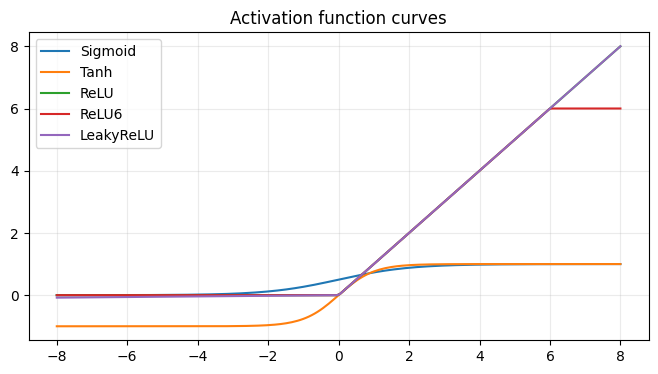

In [4]:
# Quan sát hình dạng của các activation trước khi so sánh quá trình học.
activation_input = torch.linspace(-8, 8, 200)
plt.figure(figsize=(8, 4))
for activation in (nn.Sigmoid, nn.Tanh, nn.ReLU, nn.ReLU6, nn.LeakyReLU):
    plt.plot(activation_input, activation()(activation_input), label=activation.__name__)
plt.title("Activation function curves")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

ReLU       | epoch 100 | BCE=0.6303 | accuracy=82.6%
ReLU       | epoch 200 | BCE=0.1950 | accuracy=98.7%
ReLU       | epoch 300 | BCE=0.0462 | accuracy=98.9%
Sigmoid    | epoch 100 | BCE=0.6933 | accuracy=50.0%
Sigmoid    | epoch 200 | BCE=0.6932 | accuracy=50.0%
Sigmoid    | epoch 300 | BCE=0.6932 | accuracy=50.0%
Tanh       | epoch 100 | BCE=0.6787 | accuracy=57.3%
Tanh       | epoch 200 | BCE=0.6411 | accuracy=61.8%
Tanh       | epoch 300 | BCE=0.6153 | accuracy=63.6%
ReLU6      | epoch 100 | BCE=0.6303 | accuracy=82.6%
ReLU6      | epoch 200 | BCE=0.1950 | accuracy=98.7%
ReLU6      | epoch 300 | BCE=0.0462 | accuracy=98.9%
LeakyReLU  | epoch 100 | BCE=0.5884 | accuracy=85.3%
LeakyReLU  | epoch 200 | BCE=0.0860 | accuracy=98.9%
LeakyReLU  | epoch 300 | BCE=0.0326 | accuracy=99.2%


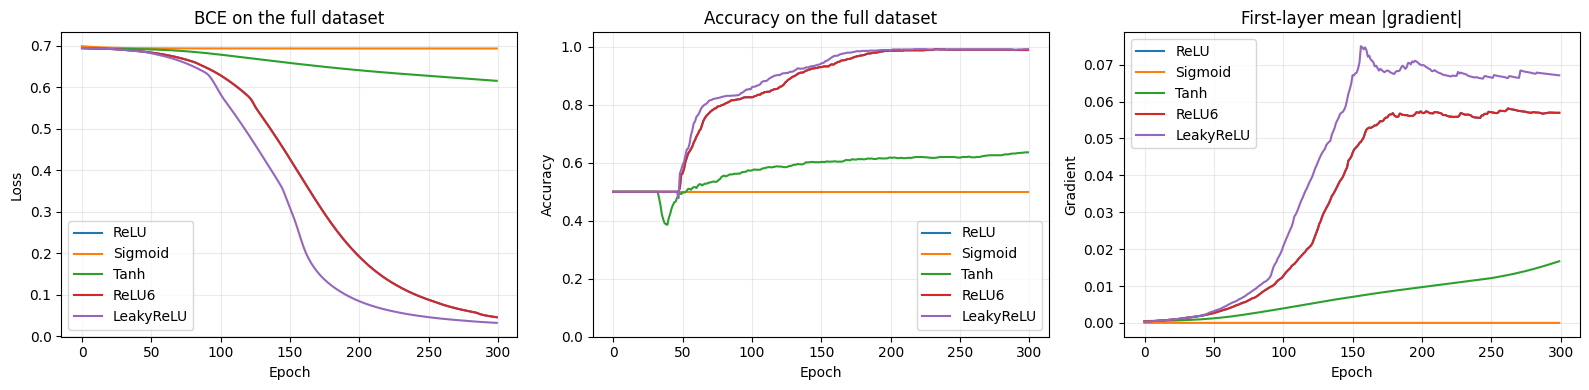

In [5]:
activation_types = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ReLU6, nn.LeakyReLU]
results = {activation.__name__: train_activation(activation) for activation in activation_types}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, (losses, accuracies, gradients) in results.items():
    axes[0].plot(losses, label=name)
    axes[1].plot(accuracies, label=name)
    axes[2].plot([layer[0] for layer in gradients], label=name)
axes[0].set(title="BCE on the full dataset", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Accuracy on the full dataset", xlabel="Epoch", ylabel="Accuracy")
axes[1].set_ylim(0, 1.05)
axes[2].set(title="First-layer mean |gradient|", xlabel="Epoch", ylabel="Gradient")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

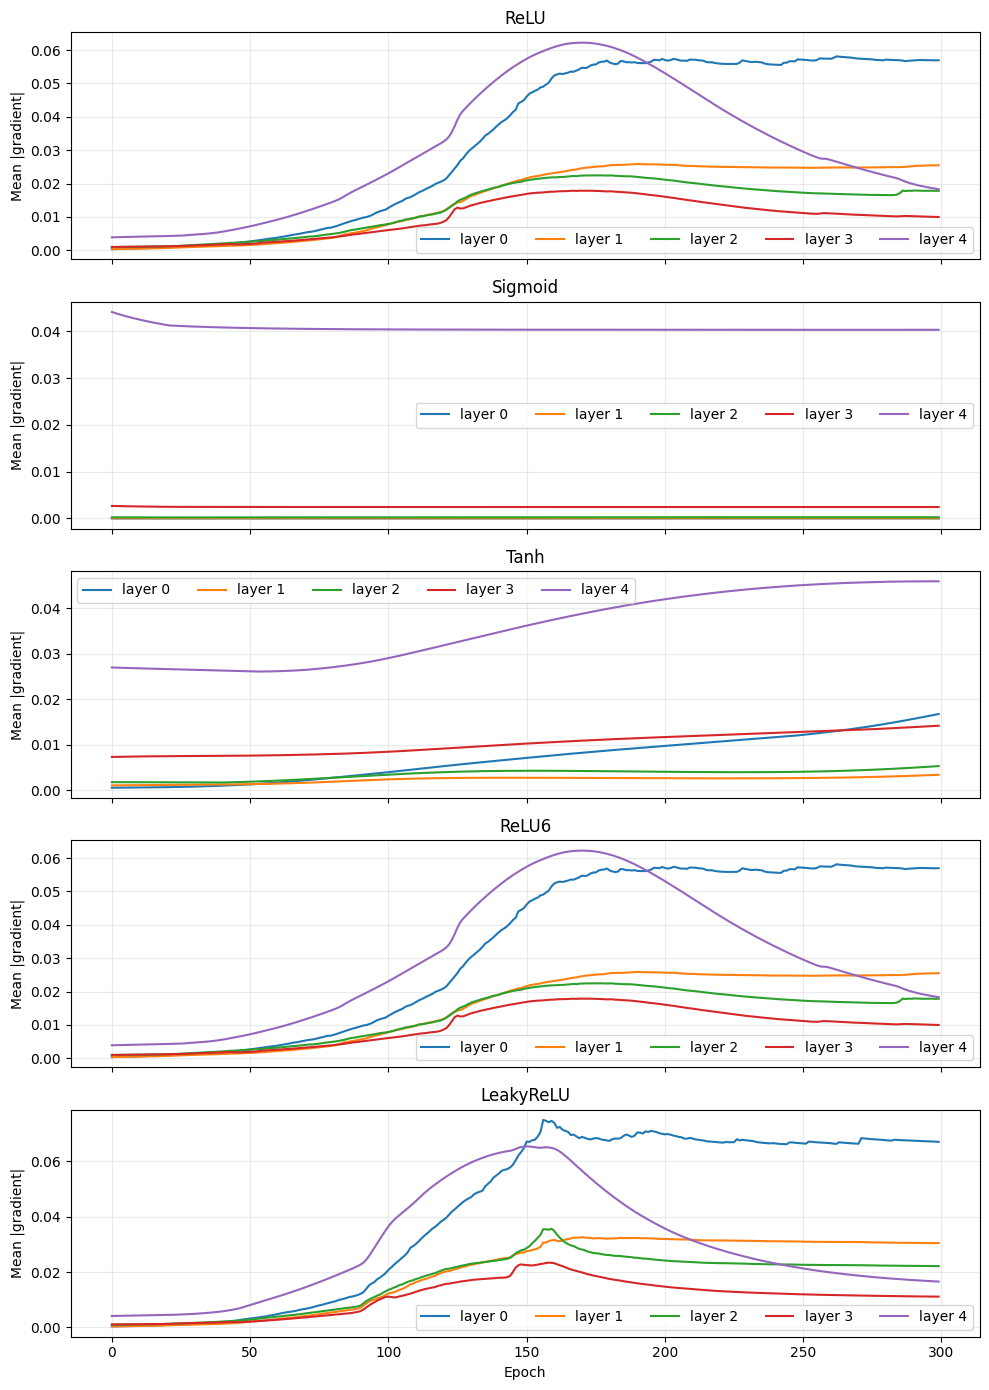

In [6]:
# Gradient trung bình tuyệt đối qua từng lớp cho mỗi activation.
fig, gradient_axes = plt.subplots(len(results), 1, figsize=(10, 14), sharex=True)
for axis, (name, (_, _, gradients)) in zip(gradient_axes, results.items()):
    for layer_index in range(5):
        axis.plot([epoch[layer_index] for epoch in gradients], label=f"layer {layer_index}")
    axis.set(title=name, ylabel="Mean |gradient|")
    axis.legend(ncol=5)
    axis.grid(alpha=0.25)
gradient_axes[-1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

Chạy đủ 300 epoch cho từng activation như thí nghiệm trong chương; trên CPU, cell này có thể mất khoảng một đến hai phút.

# <center>**HẾT**<center>